# Семинар 1. Линейная регрессия

#### Шаг 1. Загрузка датасета и вывод на экран

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 100)
data = pd.read_csv("delivery_dataset.csv")
display(data)
print("Размер датасета:", data.shape)
print("Пропуски:", data.isna().sum().sum())

Размер датасета: (500, 8)
Пропуски: 0


,Дата заказа (ГГГГ-ММ-ДД),Шифр заказа (ID),Расстояние до клиента (в км),Количество позиций в чеке (в шт.),Балл пробок на дорогах (в баллах),Погода (в градусах Цельсия),Этаж доставки (в этажах),Время доставки (в минутах)
0,2026-09-08,ORD-202608001,11.3,1,9,21.0,6,79.2
1,2026-08-29,ORD-202608002,7.3,3,7,27.0,7,46.6
2,2026-08-15,ORD-202608003,2.2,1,3,20.0,5,16.3
3,2026-08-08,ORD-202608004,0.9,2,6,22.9,1,15.8
4,2026-08-21,ORD-202608005,12.3,14,4,18.1,2,69.2
...,...,...,...,...,...,...,...,...
495,2026-08-12,ORD-202608496,5.2,2,3,18.0,9,28.9
496,2026-08-09,ORD-202608497,10.0,3,4,21.6,10,48.0
497,2026-08-07,ORD-202608498,5.5,3,2,9.5,3,27.0
498,2026-08-28,ORD-202608499,7.1,6,4,13.5,1,40.4


#### Шаг2. Разделение выборки на тренировочную, валидационную и тестовую с выбором нужных столбцов:
* в тренировочной: 300 первых заказов;
* в валидационной: 100 следующих; 
* в тестовой: 100 последних.

In [2]:
features = [
    "Расстояние до клиента (в км)",
    "Количество позиций в чеке (в шт.)",
    "Балл пробок на дорогах (в баллах)",
    "Погода (в градусах Цельсия)",
    "Этаж доставки (в этажах)"
]
target = "Время доставки (в минутах)"

X_train = data.iloc[:300][features]
y_train = data.iloc[:300][target]
X_val = data.iloc[300:400][features]
y_val = data.iloc[300:400][target]
X_test = data.iloc[400:][features]
y_test = data.iloc[400:][target]

print("Размеры выборок:", len(X_train), len(X_val), len(X_test))

Размеры выборок: 300 100 100


#### Вопрос 1. 

Для чего мы разбиваем данные на выборки? Для чего нам нужна тренировачная, для чего валидационная, для чего тестовая?

Данные разбиваем на выборки чтобы лучше обучить модель. train нужна чтобы подобрать коэффициенты, val чтобы подобрать подходящие параметры и проверить правильно ли мы подобрали коэффициенты, test нужна чтобы проверить работу обученной модели

#### Шаг 3. Установка sklearn чтобы обучать модель линейной регрессии через Ridge

In [3]:
%pip install -q --disable-pip-version-check scikit-learn

Note: you may need to restart the kernel to use updated packages.


#### Шаг 4. Обучение модели линейной регрессии на тренировочной выборке с помощью Ridge и sparse_cg

In [4]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=0.0, solver="sparse_cg", tol=1e-12, max_iter=100)
model.fit(X_train, y_train)

display(pd.Series(model.coef_, index=features, name="Коэффициент"))
print("Свободный член:", model.intercept_)

Свободный член: -2.9673282180037432


Расстояние до клиента (в км)         4.396127
Количество позиций в чеке (в шт.)    0.835327
Балл пробок на дорогах (в баллах)    2.153894
Погода (в градусах Цельсия)         -0.047348
Этаж доставки (в этажах)             0.343231
Name: Коэффициент, dtype: float64

#### Шаг 5. Вывод на экран графиков ошибок (SSE, MSE, RMSE) в зависимости от итераций для train и val выборок.

Число итераций: 5
Норма невязки: 3.628684429044091e-13
Ручное решение совпадает с Ridge: True


,iteration,SSE train,SSE val,MSE train,MSE val,RMSE train,RMSE val
0,0,211009.701867,72207.381378,703.365673,722.073814,26.521042,26.871431
1,1,12930.233097,3662.411544,43.100777,36.624115,6.565118,6.051786
2,2,9382.164498,2919.239968,31.273882,29.192400,5.592306,5.402999
3,3,6077.896168,2109.703091,20.259654,21.097031,4.501073,4.593150
4,4,5728.926281,2075.766273,19.096421,20.757663,4.369945,4.556058
5,5,5529.134406,2078.505245,18.430448,20.785052,4.293070,4.559063


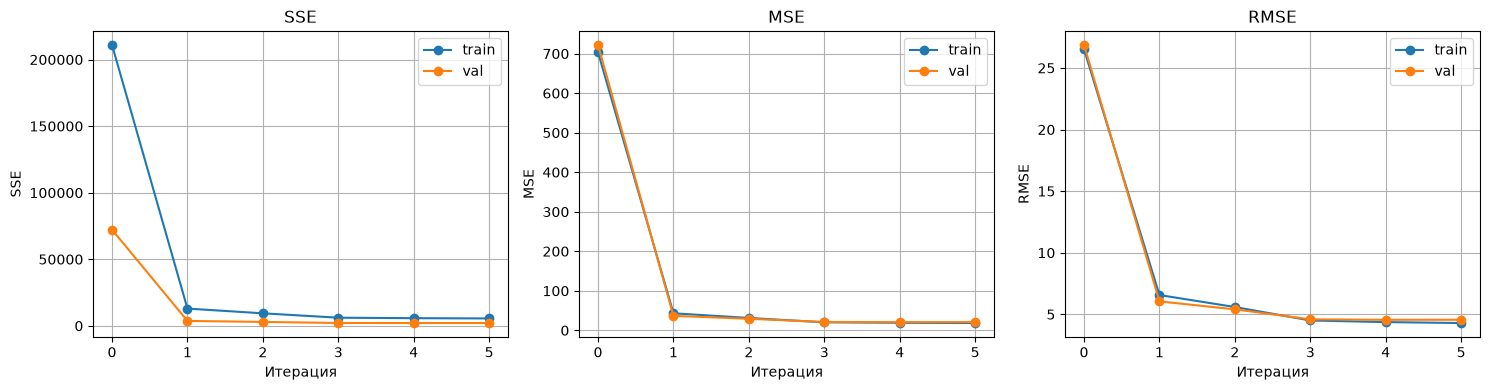

In [5]:
# Центрируем по train, чтобы учесть свободный член, как в Ridge.
x_mean = X_train.mean().to_numpy()
y_mean = y_train.mean()
X = X_train.to_numpy() - x_mean
y = y_train.to_numpy() - y_mean
Xv = X_val.to_numpy() - x_mean

A = X.T @ X
b = X.T @ y
w = np.zeros(X.shape[1])
r = b - A @ w
p = r.copy()

epsilon = 1e-8
max_iter = 100
history = []

for iteration in range(max_iter + 1):
    train_error = X @ w + y_mean - y_train.to_numpy()
    val_error = Xv @ w + y_mean - y_val.to_numpy()
    sse_train = np.sum(train_error ** 2)
    sse_val = np.sum(val_error ** 2)
    mse_train = sse_train / len(y_train)
    mse_val = sse_val / len(y_val)
    history.append([iteration, sse_train, sse_val, mse_train, mse_val,
                    np.sqrt(mse_train), np.sqrt(mse_val)])

    # Критерий из лекции: норма невязки меньше epsilon.
    if np.linalg.norm(r) < epsilon or iteration == max_iter:
        break

    step = (r @ r) / (p @ A @ p)
    w = w + step * p
    r_new = r - step * (A @ p)
    beta = (r_new @ r_new) / (r @ r)
    p = r_new + beta * p
    r = r_new

history = pd.DataFrame(history, columns=[
    "iteration", "SSE train", "SSE val", "MSE train", "MSE val",
    "RMSE train", "RMSE val"
])
display(history.round(6))
print("Число итераций:", iteration)
print("Норма невязки:", np.linalg.norm(r))
print("Ручное решение совпадает с Ridge:",
      np.allclose(Xv @ w + y_mean, model.predict(X_val), atol=1e-6, rtol=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["SSE", "MSE", "RMSE"]):
    ax.plot(history["iteration"], history[metric + " train"], "o-", label="train")
    ax.plot(history["iteration"], history[metric + " val"], "o-", label="val")
    ax.set_title(metric)
    ax.set_xlabel("Итерация")
    ax.set_ylabel(metric)
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

#### Вопрос 2.

Какую информацию про нашу модель несут эти графики?

Эти графики показывают как обучается модель и уменьшаются ли ошибки.

#### Вопрос 3. 

Какая траектория линий train и val ошибок будет на графиках недообученной модели и почему?

Какая траектория линий train и val ошибок будет на графиках обученной модели и почему?

Какая траектория линий train и val ошибок будет на графиках переобученной модели и почему?

У недообученной модели обе ошибки останутся высокими и недостигнут минимума. Изза того что слишком простая модель или мало итераций
У обученной модели обе ошибки падают и стабилизируются. Это значит что модель уловила основные зависимости и работает на новых данных
У переобученной модели ошибки train уменьшаются а ошибки val после достижения минимума начинает возрастать. Небольшое колебание не означает что модель переобучилась. Это возникает потому что модель подстроилась под особенности тренировочных данных.

#### Шаг 6. Применение модели на тестовой выборке

In [6]:
y_predict = model.predict(X_test)

result = pd.DataFrame({
    "ID заказа": data.iloc[400:]["Шифр заказа (ID)"].to_numpy(),
    "Прогноз времени, мин": y_predict,
    "Настоящее время, мин": y_test.to_numpy(),
    "Разница, мин": y_predict - y_test.to_numpy()
})
display(result.round(2))

,ID заказа,"Прогноз времени, мин","Настоящее время, мин","Разница, мин"
0,ORD-202608401,33.07,33.9,-0.83
1,ORD-202608402,33.13,33.1,0.03
2,ORD-202608403,20.85,16.3,4.55
3,ORD-202608404,34.39,34.7,-0.31
4,ORD-202608405,17.56,13.3,4.26
5,ORD-202608406,42.81,39.3,3.51
6,ORD-202608407,37.45,36.3,1.15
7,ORD-202608408,12.35,11.9,0.45
8,ORD-202608409,59.05,56.5,2.55
9,ORD-202608410,32.08,35.9,-3.82


#### Шаг 7. RMSE на тестовой выборке

In [7]:
rmse_test = np.sqrt(np.mean((y_predict - y_test.to_numpy()) ** 2))
print(f"RMSE на тестовой выборке: {rmse_test:.2f} мин")

RMSE на тестовой выборке: 4.83 мин


#### Вопрос 4.

Что получившийся RMSE может сказать о нашей модели?

RMSE на тренировочной выборке равна 4,83мин. Большие промахи влияют на нее сильнее. Если для задачи погрешность примерно 5 минут приемлема то результат можно считать приемлемым. Однако это не значит что ошибка каждого прогноза меньше 5 минут.